# Нейросетевой анализ требований работодателей: извлечение навыков из вакансий

Весь пайплайн в одном ноутбуке, ячейки запускаются **сверху вниз по порядку**:

1. установка пакетов и настройки;
2. загрузка данных (Mendeley, вакансии в сфере ИИ) и динамика заявленных навыков;
3. baseline: поиск навыков по словарю;
4. слабая BIO-разметка текстов;
5. дообучение BERT (token classification) и сравнение с baseline.

In [6]:
%pip install -q pymorphy3 pymorphy3-dicts-ru "accelerate>=1.1.0" transformers pandas matplotlib

In [7]:
import os, re, ast, json, glob, random
from collections import Counter
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymorphy3

MODEL_NAME = "DeepPavlov/rubert-base-cased"
EPOCHS = 6
LR = 3e-5
BATCH = 16
CHUNK = 100
MAX_LEN = 384
RUN_TRAINING = True
KEEP_ALL_ROLES = False
MIN_FREQ = 5
SEED = 42
OUT_DIR = "ner_model"

random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

In [8]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive не подключён (это нормально вне Colab):", type(e).__name__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
_morph = pymorphy3.MorphAnalyzer()
TOKEN_RE = re.compile(r"\w+[+#]*|[^\w\s]")
CYR_RE = re.compile(r"[а-яё]", re.I)

LABELS = ["O", "B-SKILL", "I-SKILL"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}

def tokenize(text):
    return TOKEN_RE.findall(text)

@lru_cache(maxsize=None)
def lemma(token):
    t = token.lower()
    if CYR_RE.search(t):
        return _morph.parse(t)[0].normal_form
    return t

def lemma_key(tokens):
    return " ".join(lemma(t) for t in tok

ALIASES = {
    "ml": "machine learning", "машинное обучение": "machine learning",
    "dl": "deep learning", "глубокое обучение": "deep learning",
    "nlp": "nlp", "обработка естественного языка": "nlp",
    "pytorch": "pytorch", "torch": "pytorch",
    "scala": "scala", "sql": "sql", "postgresql": "postgresql",
    "k8s": "kubernetes", "kafka": "apache kafka",
    "анализ данных": "data analysis", "data analysis": "data analysis",
    "pandas": "pandas", "numpy": "numpy",
}
ALIAS_GROUPS = {}
for _raw, _canon in ALIASES.items():
    ALIAS_GROUPS.setdefault(_canon, {_canon}).add(_raw)

def normalize(skill):
    s = re.sub(r"\s+", " ", str(skill).strip().lower())
    return ALIASES.get(s, s)

def skill_variants(skill):
    skill = skill.strip().lower()
    variants = {skill} | ALIAS_GROUPS.get(skill, set())
    if skill.startswith("apache "):
        variants.add(skill[len("apache "):])
    for suffix in (" framework", " core"):
        if skill.endswith(suffix):
            variants.add(skill[: -len(suffix)])
    return variants

def parse_skills(raw):
    if pd.isna(raw):
        return []
    try:
        items = ast.literal_eval(raw)
    except (ValueError, SyntaxError):
        return []
    return sorted({normalize(x) for x in items if str(x).strip()})

print("Проверка лемматизации:", lemma("статистического"), "|", lemma("обучения"))

Проверка лемматизации: статистический | обучение


## 1. Данные

Ищем файл в текущей папке, в `/content` и в корне Google Drive. Если есть исходный CSV, читаем его, иначе берём `vacancies_clean.csv`.

In [10]:
def find_file(patterns):
    for d in [".", "/content", "/content/drive/MyDrive"]:
        for p in patterns:
            hits = sorted(glob.glob(os.path.join(d, p)))
            if hits:
                return hits[0]
    return None


RAW = find_file(["*artificial*intelligence*.csv"])
CLEAN = find_file(["vacancies_clean.csv"])
print("Исходный файл:", RAW)
print("Очищенный файл:", CLEAN)

RELEVANT_ROLES = {
    "Программист, разработчик", "Дата-сайентист", "Аналитик",
    "BI-аналитик, аналитик данных", "Руководитель группы разработки",
    "Тестировщик", "DevOps-инженер", "Системный администратор",
    "Системный инженер", "Сетевой инженер", "Архитектор", "Другое",
}

if RAW:
    df = pd.read_csv(RAW, encoding="utf-8-sig")
    print("Размер исходной таблицы:", df.shape)
    df["date"] = pd.to_datetime(df["last_found_at"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
    df["skills"] = df["raw_skills"].apply(parse_skills)
    if not KEEP_ALL_ROLES:
        before = len(df)
        df = df[df["role_name"].isin(RELEVANT_ROLES)].copy()
        print(f"После фильтра по ролям: {len(df)} из {before}")
elif CLEAN:
    df = pd.read_csv(CLEAN, encoding="utf-8-sig")
    df["skills"] = df["skills"].fillna("").apply(lambda s: [x for x in s.split("|") if x])
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    print("Прочитан очищенный файл:", df.shape)
else:
    raise FileNotFoundError(
        "Не найден ни 'vacancies_artificial intelligence.csv', ни 'vacancies_clean.csv'. "
        "Положите файл рядом с ноутбуком, в /content или в корень Google Drive.")

df["month"] = df["date"].dt.to_period("M")
df["n_skills"] = df["skills"].str.len()
print("Период:", df["date"].min().date(), "->", df["date"].max().date())
print("Не разобрано дат:", int(df["date"].isna().sum()))
print("Вакансий без навыков:", int((df["n_skills"] == 0).sum()),
      "| навыков на вакансию: среднее %.1f" % df["n_skills"].mean())

Исходный файл: /content/drive/MyDrive/vacancies_artificial intelligence.csv
Очищенный файл: None
Размер исходной таблицы: (3626, 34)
После фильтра по ролям: 2673 из 3626
Период: 2023-10-10 -> 2024-05-27
Не разобрано дат: 0
Вакансий без навыков: 479 | навыков на вакансию: среднее 4.8


## 2. Динамика заявленных навыков по месяцам

Доля вакансий месяца, где работодатель указал навык. Месяцы, где меньше 100 вакансий, на графике не показаны, потому что доли там шумные.

Уникальных навыков: 598 | встретившихся 1 раз: 200
python              1683
machine learning    1322
sql                  609
pytorch              473
nlp                  334
postgresql           306
docker               297
git                  268
linux                259
data analysis        254
pandas               215
big data             211
английский язык      208
tensorflow           205
computer vision      181

Вакансий по месяцам:
month
2023-10     15
2023-11    343
2023-12    363
2024-01    322
2024-02    461
2024-03    471
2024-04    422
2024-05    276
Freq: M

Доля вакансий с навыком, % (топ-10):
skills   python  machine learning   sql  pytorch   nlp  postgresql  docker   git  linux  data analysis
month                                                                                                 
2023-11    70.0              55.1  15.2     13.7   8.7         5.0    10.2   7.9    5.2            7.9
2023-12    63.4              44.6  27.3     19.0  14.3         9.1    1

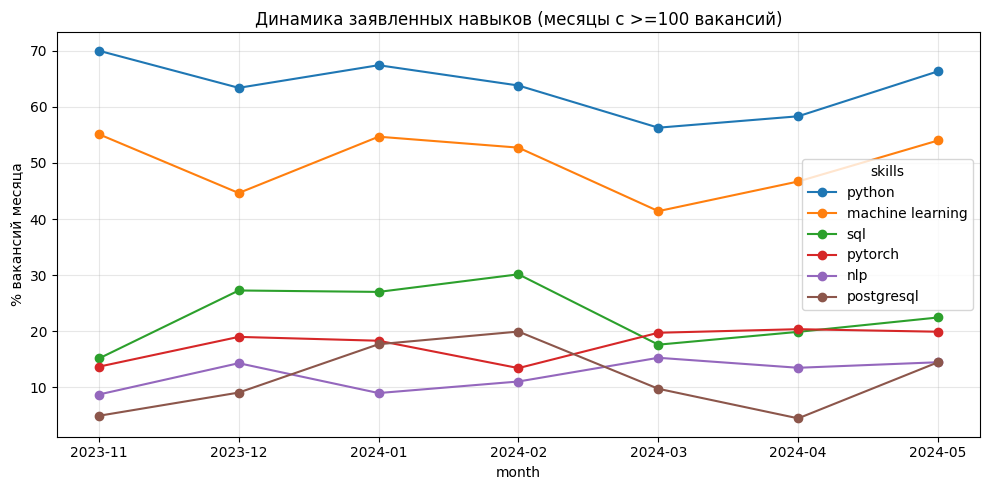

In [11]:
counter = Counter(s for lst in df["skills"] for s in lst)
top = pd.Series(counter).sort_values(ascending=False)
print("Уникальных навыков:", len(top), "| встретившихся 1 раз:", int((top == 1).sum()))
print(top.head(15).to_string())

vac_per_month = df.groupby("month").size().rename("vacancies")
exploded = df[["month", "skills"]].explode("skills").dropna(subset=["skills"])
share = exploded.groupby(["month", "skills"]).size().unstack(fill_value=0).div(vac_per_month, axis=0)
reliable = vac_per_month[vac_per_month >= 100].index
top10 = top.head(10).index.tolist()

print("\nВакансий по месяцам:")
print(vac_per_month.to_string())
print("\nДоля вакансий с навыком, % (топ-10):")
print((share.loc[reliable, top10] * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
plot_data = share.loc[reliable, top10[:6]] * 100
plot_data.index = plot_data.index.astype(str)
plot_data.plot(ax=ax, marker="o")
ax.set_ylabel("% вакансий месяца")
ax.set_title("Динамика заявленных навыков (месяцы с >=100 вакансий)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Baseline: поиск навыков по словарю

Словарь составлен из навыков, которые работодатели указали в форме (частота не меньше `MIN_FREQ`). Ищем их в тексте точным совпадением строки. Метрики считаем против заявленных навыков (это слабая разметка), поэтому **precision занижена**: в тексте часто названы навыки, которые работодатель в форме не отметил.

In [12]:
df["text"] = df["description"].fillna("").str.lower()

vocab = sorted((s for s, c in counter.items() if c >= MIN_FREQ and len(s) > 1),
               key=len, reverse=True)
patterns = {s: re.compile(r"(?<![\w+#])" + re.escape(s) + r"(?![\w+#])") for s in vocab}
df["pred_simple"] = df["text"].apply(lambda t: {s for s, p in patterns.items() if p.search(t)})

lab = df[df["skills"].str.len() > 0].copy()
lab["gold"] = lab["skills"].apply(lambda l: {s for s in l if s in patterns})
lab = lab[lab["gold"].str.len() > 0]

tp = sum(len(g & p) for g, p in zip(lab["gold"], lab["pred_simple"]))
fp = sum(len(p - g) for g, p in zip(lab["gold"], lab["pred_simple"]))
fn = sum(len(g - p) for g, p in zip(lab["gold"], lab["pred_simple"]))
P = tp / (tp + fp); R = tp / (tp + fn); F = 2 * P * R / (P + R)
print(f"Словарь: {len(vocab)} навыков, вакансий с разметкой: {len(lab)}")
print(f"Baseline (простой поиск строки): Precision {P:.3f} | Recall {R:.3f} | F1 {F:.3f}")

Словарь: 209 навыков, вакансий с разметкой: 2185
Baseline (простой поиск строки): Precision 0.395 | Recall 0.564 | F1 0.465


## 4. Слабая BIO-разметка

Для каждой вакансии заявленные навыки ищем в тексте **с лемматизацией** («машинного обучения» находится по навыку «машинное обучение») и с разворачиванием синонимов (`ML`, `Машинное обучение` → `machine learning`). Найденные спаны получают метки `B-SKILL` / `I-SKILL`, остальные токены `O`.

Ограничение: размечены только навыки из формы работодателя. Навыки, названные в тексте, но не отмеченные в форме, остаются меткой `O`, это шум в разметке.

In [13]:
d_lab = df[df["skills"].str.len() > 0].reset_index(drop=True)
print("Вакансий с заявленными навыками:", len(d_lab))

variant_map = {}
unmatched = Counter()
declared_total = matched_total = 0
records = []

for _, row in d_lab.iterrows():
    words = tokenize(str(row["description"]))
    lemmas = [lemma(w) for w in words]

    pats = []
    for skill in row["skills"]:
        canon = lemma_key(tokenize(skill))
        for var in skill_variants(skill):
            toks = tokenize(var)
            if not toks:
                continue
            variant_map[lemma_key(toks)] = canon
            pats.append((tuple(lemma(t) for t in toks), canon))
    pats.sort(key=lambda p: len(p[0]), reverse=True)

    labels = [0] * len(words)
    found = set()
    for plems, canon in pats:
        n = len(plems)
        for i in range(len(lemmas) - n + 1):
            if tuple(lemmas[i:i + n]) == plems and all(l == 0 for l in labels[i:i + n]):
                labels[i] = LABEL2ID["B-SKILL"]
                for j in range(i + 1, i + n):
                    labels[j] = LABEL2ID["I-SKILL"]
                found.add(canon)

    declared = {lemma_key(tokenize(s)) for s in row["skills"]}
    declared_total += len(declared)
    matched_total += len(found & declared)
    for s in row["skills"]:
        if lemma_key(tokenize(s)) not in found:
            unmatched[s] += 1

    if found:
        records.append({"id": str(row["id"]), "month": str(row["month"]),
                        "words": words, "labels": labels, "gold": sorted(found)})

print(f"Заявленных навыков найдено в тексте: {matched_total / declared_total:.1%}")
print("Вакансий с хотя бы одним размеченным навыком:", len(records))
n_tok = sum(len(r["words"]) for r in records)
n_skill = sum(sum(1 for l in r["labels"] if l) for r in records)
print(f"Токенов: {n_tok}, из них в навыках: {n_skill} ({n_skill / n_tok:.2%})")
print("Чаще всего НЕ найденные заявленные навыки:", unmatched.most_common(10))

random.Random(SEED).shuffle(records)
n = len(records)
for i, r in enumerate(records):
    r["split"] = "train" if i < 0.8 * n else ("val" if i < 0.9 * n else "test")
split = {s: [r for r in records if r["split"] == s] for s in ("train", "val", "test")}
print("Разбиение:", {k: len(v) for k, v in split.items()})

with open("bio_data.jsonl", "w", encoding="utf-8") as f:
    for r in records:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")
with open("variant_map.json", "w", encoding="utf-8") as f:
    json.dump(variant_map, f, ensure_ascii=False)

Вакансий с заявленными навыками: 2194
Заявленных навыков найдено в тексте: 66.6%
Вакансий с хотя бы одним размеченным навыком: 2108
Токенов: 770634, из них в навыках: 17133 (2.22%)
Чаще всего НЕ найденные заявленные навыки: [('английский язык', 178), ('data analysis', 175), ('postgresql', 170), ('big data', 158), ('базы данных', 137), ('статистический анализ', 128), ('sql', 126), ('python', 116), ('аналитическое мышление', 115), ('computer vision', 113)]
Разбиение: {'train': 1687, 'val': 211, 'test': 210}


## 5. Обучение BERT (token classification)

Проверяем доступное устройство. Если GPU нет, обучение будет очень долгим.

In [14]:
import torch
from torch.utils.data import Dataset
from transformers import (AutoModelForTokenClassification, AutoTokenizer,
                          DataCollatorForTokenClassification, Trainer,
                          TrainingArguments, set_seed)

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # для Mac с Apple Silicon
set_seed(SEED)

if torch.cuda.is_available():
    print("Устройство: GPU", torch.cuda.get_device_name(0))
elif torch.backends.mps.is_available():
    print("Устройство: Apple MPS")
else:
    print("Устройство: CPU. Обучение будет очень долгим. В Colab включите GPU "
          "(Runtime -> Change runtime type) или поставьте MODEL_NAME = 'cointegrated/rubert-tiny2'.")
print("torch", torch.__version__)

Устройство: GPU Tesla T4
torch 2.11.0+cu130


In [15]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)


def chunks(doc):
    w, l = doc["words"], doc["labels"]
    for i in range(0, len(w), CHUNK):
        yield w[i:i + CHUNK], l[i:i + CHUNK]


class NerData(Dataset):
    def __init__(self, documents, keep_empty=0.3):
        self.items = []
        rng = np.random.RandomState(0)
        for d in documents:
            for words, labels in chunks(d):
                if not any(labels) and rng.rand() > keep_empty:
                    continue
                enc = tok(words, is_split_into_words=True, truncation=True, max_length=MAX_LEN)
                lab, prev = [], None
                for wid in enc.word_ids():
                    lab.append(-100 if wid is None or wid == prev else labels[wid])
                    prev = wid
                enc["labels"] = lab
                self.items.append(dict(enc))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        return self.items[i]


def spans(seq):
    out, start = set(), None
    for i, x in enumerate(list(seq) + [0]):
        if x == 1:                          # B
            if start is not None:
                out.add((start, i))
            start = i
        elif x == 2 and start is not None:  # I
            continue
        else:
            if start is not None:
                out.add((start, i))
            start = None
    return out


def prf(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    tp = fp = fn = 0
    for p, l in zip(preds, labels):
        mask = l != -100
        ps, ls = spans(p[mask]), spans(l[mask])
        tp += len(ps & ls); fp += len(ps - ls); fn += len(ls - ps)
    p, r, f = prf(tp, fp, fn)
    return {"precision": p, "recall": r, "f1": f}


train_ds, val_ds = NerData(split["train"]), NerData(split["val"], keep_empty=1.0)
print("Фрагментов: train", len(train_ds), "| val", len(val_ds))

config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.65M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Фрагментов: train 4804 | val 872


In [16]:
if RUN_TRAINING:
    model = AutoModelForTokenClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS),
        id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)})

    total_steps = -(-len(train_ds) // BATCH) * EPOCHS
    warmup_steps = int(0.1 * total_steps)
    print(f"Шагов обучения: {total_steps}, из них разогрев: {warmup_steps}")

    trainer = Trainer(
        model=model,
        args=TrainingArguments(
            output_dir="ner_runs", num_train_epochs=EPOCHS, learning_rate=LR,
            per_device_train_batch_size=BATCH, per_device_eval_batch_size=32,
            weight_decay=0.01, warmup_steps=warmup_steps,
            eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
            load_best_model_at_end=True, metric_for_best_model="f1",
            fp16=torch.cuda.is_available(),   # ускоряет обучение на GPU
            logging_steps=50, report_to="none", seed=SEED),
        train_dataset=train_ds, eval_dataset=val_ds,
        data_collator=DataCollatorForTokenClassification(tok),
        compute_metrics=compute_metrics, processing_class=tok)
    trainer.train()
    trainer.save_model(OUT_DIR)
    tok.save_pretrained(OUT_DIR)
    print("Модель сохранена в", OUT_DIR)
else:
    print("RUN_TRAINING = False: обучение пропущено")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  714MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: DeepPavlov/rubert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can 

... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Модель сохранена в ner_model


## 6. Оценка на тесте: BERT против словарного baseline

Сравнение на уровне вакансии: множество найденных навыков (приведённых к канону) против заявленных навыков, найденных в тексте. Словарь baseline строится **только по обучающей выборке**, чтобы сравнение было честным.

In [17]:
if RUN_TRAINING:
    model = trainer.model.eval()
    device = next(model.parameters()).device

    def to_canon(words):
        k = lemma_key(words)
        return variant_map.get(k, k)

    @torch.no_grad()
    def predict_doc(doc):
        found = set()
        for words, _ in chunks(doc):
            enc = tok(words, is_split_into_words=True, truncation=True,
                      max_length=MAX_LEN, return_tensors="pt")
            pred = model(**{k: v.to(device) for k, v in enc.items()}).logits[0].argmax(-1).cpu().numpy()
            wp, prev = [0] * len(words), None
            for ti, wid in enumerate(enc.word_ids()):
                if wid is not None and wid != prev:
                    wp[wid] = int(pred[ti])
                prev = wid
            for s, e in spans(wp):
                found.add(to_canon(words[s:e]))
        return found

    train_vocab = Counter(g for d in split["train"] for g in d["gold"])
    vocab_seqs = sorted(((tuple(k.split()), k) for k, c in train_vocab.items() if c >= MIN_FREQ),
                        key=lambda x: len(x[0]), reverse=True)

    def baseline_doc(doc):
        lem = [lemma(w) for w in doc["words"]]
        found = set()
        for seq, key in vocab_seqs:
            n = len(seq)
            if any(tuple(lem[i:i + n]) == seq for i in range(len(lem) - n + 1)):
                found.add(key)
        return found

    results = {}
    for name, fn_ in (("baseline (словарь+леммы)", baseline_doc), ("BERT", predict_doc)):
        tp = fp = fn = 0
        for d in split["test"]:
            pred, gold = fn_(d), set(d["gold"])
            tp += len(pred & gold); fp += len(pred - gold); fn += len(gold - pred)
        p, r, f = prf(tp, fp, fn)
        results[name] = {"precision": p, "recall": r, "f1": f}
        print(f"{name:28s} P={p:.3f}  R={r:.3f}  F1={f:.3f}")

    with open("test_metrics.json", "w", encoding="utf-8") as f:
        json.dump(results, f, ensure_ascii=False, indent=2)
else:
    print("Обучение пропущено, оценивать нечего")

baseline (словарь+леммы)     P=0.394  R=0.796  F1=0.527
BERT                         P=0.733  R=0.845  F1=0.785


## 7. Сохранение результатов

В Colab всё, что лежит в `/content`, пропадает при отключении среды. Копируем результаты на Google Drive (если он подключён).

In [18]:
import shutil

target = "/content/drive/MyDrive/kurs_results"
if os.path.isdir("/content/drive/MyDrive"):
    os.makedirs(target, exist_ok=True)
    for name in ["bio_data.jsonl", "variant_map.json", "test_metrics.json"]:
        if os.path.exists(name):
            shutil.copy(name, target)
    if os.path.isdir(OUT_DIR):
        shutil.copytree(OUT_DIR, os.path.join(target, OUT_DIR), dirs_exist_ok=True)
    print("Результаты скопированы в", target)
else:
    print("Drive не подключён: результаты остались в текущей папке (", os.getcwd(), ")")

Результаты скопированы в /content/drive/MyDrive/kurs_results
